**Author:**

Kumar Jayant

# Customer segments are not isolated islands; they are continuum of probabilities

Companion notebook to the aimldl.io post *Customer segments are not isolated islands; they are continuum of probabilities: Affinity segmentation for targeting, positioning and competitive threat analysis*. The blog explains the approach; this notebook runs it end to end.

**Data:** [jPhone: Customer Affinity Segmentation](https://www.kaggle.com/datasets/krjynt/jphone-customer-affinity-segmentation) (CC0: Public Domain). It has two files:
- `jphone_customer_profiles.csv`: 300 simulated customers, one row each. Each row holds how much each of six attributes matters to the customer (brand, price, camera, battery, screen, memory; adds up to 100), how much they like each level of each attribute (1 to 7), and a profile: age, income, profession, marital status and daily hours on the phone. A `customer_type` column holds each customer's simulated type; it is not used in the analysis.
- `market_phones.csv`: the four phones in the market: jPhone P4 and P1, shortlisted in the previous post, and the rivals Phone X and Phone Y.

The data is fully simulated. It is used as an illustration of the approach, not as evidence about the phone market.

**Method Used:** **affinity segmentation**, the algorithmic-analytical approach works out each customer's probability of buying each phone, with a **logit** model instead of placing each customer in one cluster, . Each phone then has its own segment, and every customer counts in every segment in proportion to that probability. Segment profiles are **probability-weighted averages**, compared with the market average through **log lifts** to find each segment's focal descriptors. **Cosine similarity** (Approaches 1 and 2) and a count of matching colours on the segment profiles (Approach 3) show who competes with whom; the brand preference table, read by rows and by columns, shows in which direction.

**What this notebook does**
- **Settings:** one cell lists the files, the phones in the market, the logit scale constant (c = 0.0139), the customer descriptors to profile and the colour cut-off for focal descriptors (±0.1). Change only this cell to run the notebook on your own data or assumptions.
- **0. Imports the dataset** from Kaggle.
- **1. Checks the input:** stops with a plain-language message if a column is missing, has blanks, or if a customer's importances don't add up to 100.
- **2. Calculates affinity scores:** scores every phone for every customer (importance × rating, summed), turns the scores into purchase probabilities with the logit, and averages them into market shares.
- **3. Profiles each affinity segment and finds its focal descriptors:** the probability-weighted average of every descriptor (importances, brand preferences, age, income, phone hours, and the share of each profession and marital status) for each phone's segment, compared with the market average through log lifts (base 10), shown as a colour-coded heatmap, with the persona each segment suggests.
- **4. Reads the competition, three ways:**
    - **Approach 1, purchase probabilities:** which phones the same customers are likely to buy.
    - **Approach 2, brand preference table:** read by rows (whose buyers resemble ours) and by columns (which brand is substitutable with ours), centred on the market average.
    - **Approach 3, segment profiles:** colour matches and opposites on the log-lift heatmap, read by observation.
- **5. Shows the asymmetry of competition** from the two Approach 2 tables.

**Using your own data:** one row per customer, no missing values. You need importances that add up to 100, a rating for every attribute level, and any profile columns you want to describe segments with (numeric or categorical). Describe your products and the rivals' on the same attributes. Fill in the settings cell and run all.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import glob, os
import kagglehub
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.colors import BoundaryNorm
from matplotlib.patches import FancyBboxPatch
import matplotlib.ticker as mticker
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler
import matplotlib.pyplot as plt
import math
from IPython.display import Math
import matplotlib.pyplot as plt
from matplotlib.patches import Patch


pd.set_option('display.float_format', lambda v: f'{v:,.2f}')
plt.rcParams.update({'figure.dpi': 120, 'axes.spines.top': False, 'axes.spines.right': False})

## Settings

Every assumption the analysis uses, in one place. Change a value here and run all cells again; nothing else needs editing.


In [2]:
# ===== Settings: all assumptions in one place =====

# Data: the Kaggle dataset and its two files
DATASET       = "krjynt/jphone-customer-affinity-segmentation"
CUSTOMER_FILE = "jphone_customer_profiles.csv"   # one row per customer
MARKET_FILE   = "market_phones.csv"              # one row per phone in the market
ID_COL        = "customer_id"

# Attributes: market-file column -> (importance column, {level as written in the market file: rating column})
# The importance columns must add up to 100 for every customer.
ATTRIBUTES = {
    "brand":   ("imp_brand",   {"jPhone": "brand_jPhone", "X": "brand_X", "Y": "brand_Y"}),
    "price":   ("imp_price",   {20000: "r_price_20k", 25000: "r_price_25k", 30000: "r_price_30k"}),
    "camera":  ("imp_camera",  {"Basic": "r_cam_basic", "Good": "r_cam_good", "Best": "r_cam_best"}),
    "battery": ("imp_battery", {"1 day": "r_bat_1day", "2 days": "r_bat_2days"}),
    "screen":  ("imp_screen",  {'6.1"': "r_scr_6_1", '6.5"': "r_scr_6_5", '6.8"': "r_scr_6_8"}),
    "memory":  ("imp_memory",  {"128 GB": "r_mem_128", "256 GB": "r_mem_256", "512 GB": "r_mem_512"}),
}

# Section 2: logit sensitivity, the same as in the new-product post. Fixed here (simulated data), not tuned to market shares.
C = 0.0139

# Section 3: customer descriptors to profile each affinity segment on
NUMERIC_DESCRIPTORS = (
    [imp for imp, _ in ATTRIBUTES.values()]          # what matters to them
    + list(ATTRIBUTES["brand"][1].values())          # brand preferences
    + ["age", "income_lakh", "phone_hours_per_day"]  # profile
)
CATEGORICAL_DESCRIPTORS = ["profession", "marital_status"]   # profiled as the share of each category

# Section 3.4: focal descriptors
LOG_BASE     = 10     # log lift = log10(segment mean / market mean)
FOCAL_CUTOFF = 0.10   # |log lift| >= 0.10 (about 26% above or 21% below the market average) -> green or red on the heatmap


## 0. Import the dataset

In [3]:
# ===== 0. Import the dataset =====
# Pulled straight from Kaggle (works in Colab and in Kaggle notebooks; cached after the first download).
matches = glob.glob(f"/kaggle/input/**/{CUSTOMER_FILE}", recursive=True)
if matches:
    DATA_DIR = os.path.dirname(matches[0])
else:
    print("Downloading dataset from Kaggle...")
    DATA_DIR = kagglehub.dataset_download(DATASET)
    # To use your own files instead, comment out the line above and set, e.g.:
    # DATA_DIR = "/content/my_data"

print("Reading data from:", DATA_DIR)

customers = pd.read_csv(os.path.join(DATA_DIR, CUSTOMER_FILE))
market    = pd.read_csv(os.path.join(DATA_DIR, MARKET_FILE))

print(f"Customers: {len(customers)} rows × {customers.shape[1]} columns")
print(f"Market:    {len(market)} phones")
display(market.style.hide(axis="index").format({"price": "₹{:,.0f}"}))

100%|██████████| 12.1k/12.1k [00:00<00:00, 16.9MB/s]

Extracting files...
Reading data from: /root/.cache/kagglehub/datasets/krjynt/jphone-customer-affinity-segmentation/versions/1
Customers: 300 rows × 34 columns
Market:    4 phones


product,brand,role,price,camera,battery,screen,memory
jPhone P4,jPhone,Ours,"₹30,000",Best,2 days,"6.8""",512 GB
jPhone P1,jPhone,Ours,"₹20,000",Good,2 days,"6.5""",128 GB
Phone X,X,Rival,"₹25,000",Good,2 days,"6.5""",128 GB
Phone Y,Y,Rival,"₹30,000",Best,1 day,"6.8""",256 GB


In [4]:
customers.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 300 entries, 0 to 299
Data columns (total 34 columns):
 #   Column                   Non-Null Count  Dtype  
---  ------                   --------------  -----  
 0   customer_id              300 non-null    object 
 1   customer_type            300 non-null    object 
 2   imp_brand                300 non-null    int64  
 3   imp_price                300 non-null    int64  
 4   imp_camera               300 non-null    int64  
 5   imp_battery              300 non-null    int64  
 6   imp_screen               300 non-null    int64  
 7   imp_memory               300 non-null    int64  
 8   brand_jPhone             300 non-null    int64  
 9   brand_X                  300 non-null    int64  
 10  brand_Y                  300 non-null    int64  
 11  r_price_20k              300 non-null    int64  
 12  r_price_25k              300 non-null    int64  
 13  r_price_30k              300 non-null    int64  
 14  r_cam_basic              3

In [5]:
customers.head()

,customer_id,customer_type,imp_brand,imp_price,imp_camera,imp_battery,imp_screen,imp_memory,brand_jPhone,brand_X,...,r_mem_512,decision_rule,dealbreaker_max_price,dealbreaker_min_battery,dealbreaker_min_memory,age,income_lakh,profession,marital_status,phone_hours_per_day
0,C001,Power user,7,21,6,10,17,39,7,4,...,7,Trade off,NaN,NaN,NaN,34,16.00,Creative / media,Married,6.00
1,C002,Power user,9,18,13,8,32,20,6,4,...,6,Trade off,NaN,NaN,NaN,32,33.00,Other salaried,Single,5.50
2,C003,Battery first,8,24,19,34,7,8,4,6,...,6,Trade off,NaN,NaN,NaN,43,12.50,Field sales,Married,3.50
3,C004,Camera lover,13,8,37,21,8,13,5,5,...,5,Trade off,NaN,NaN,NaN,22,7.50,Creative / media,Single,4.00
4,C005,Value seeker,20,47,9,10,3,11,3,6,...,5,Screen first,"30,000.00",2 days,128 GB,25,3.00,Student,Married,4.00


## 1. Check the input

Before any scoring, make sure the data is complete and consistent. The cell lists every problem it finds in plain language and stops; if all is well, it prints one line and the notebook carries on.

It checks that:
1. Every column named in the settings is in the files.
2. There are no blanks in the columns the analysis uses .
3. Each customer's importances add up to 100.
4. Every rating is between 1 and 7.
5. Every phone's level has a rating column in `ATTRIBUTES`.

In [6]:
# ===== 1. Check the input =====
problems = []

# 1. Every column the settings name is in the customer file
rating_cols = [col for _, levels in ATTRIBUTES.values() for col in levels.values()]
imp_cols    = [imp for imp, _ in ATTRIBUTES.values()]
needed = [ID_COL] + imp_cols + rating_cols + NUMERIC_DESCRIPTORS + CATEGORICAL_DESCRIPTORS
needed = list(dict.fromkeys(needed))          # drop repeats, keep order
missing = [c for c in needed if c not in customers.columns]
if missing:
    problems.append(f"Missing from {CUSTOMER_FILE}: {', '.join(missing)}")

# The market file needs a product column and one column per attribute
missing_mk = [c for c in ["product"] + list(ATTRIBUTES) if c not in market.columns]
if missing_mk:
    problems.append(f"Missing from {MARKET_FILE}: {', '.join(missing_mk)}")

if not problems:
    # 2. No blanks in the columns the analysis uses
    blanks = customers[needed].isna().sum()
    blanks = blanks[blanks > 0]
    if len(blanks):
        problems.append("Blank values in: " + ", ".join(f"{c} ({n})" for c, n in blanks.items()))

    # 3. Each customer's importances add up to 100
    totals = customers[imp_cols].sum(axis=1)
    off = customers.loc[totals != 100, ID_COL]
    if len(off):
        problems.append(f"{len(off)} customer(s) whose importances don't add up to 100, e.g. {', '.join(off.head(5))}")

    # 4. Ratings are between 1 and 7
    out_of_range = [c for c in rating_cols if not customers[c].between(1, 7).all()]
    if out_of_range:
        problems.append("Ratings outside 1–7 in: " + ", ".join(out_of_range))

    # 5. Every phone's level has a rating column
    for _, phone in market.iterrows():
        for attr, (_, levels) in ATTRIBUTES.items():
            if phone[attr] not in levels:
                problems.append(f"{phone['product']}: {attr} level '{phone[attr]}' has no rating column in ATTRIBUTES")


if problems:
    print("Please fix these before going further:")
    for p in problems:
        print(" •", p)
    raise ValueError("Input check failed. See the list above.")

print(f"Checks passed: {len(customers)} customers, {len(market)} phones, "
      f"{len(ATTRIBUTES)} attributes. Ready to score.")

Checks passed: 300 customers, 4 phones, 6 attributes. Ready to score.


## 2. Calculate affinity scores

Every customer gets a probability of buying each phone in the market. These probabilities are the **affinity scores**: they decide who belongs to each phone's segment, and how much.

1. **The phones in the market:** all four phones side by side on the same six attributes, then each of our phones next to its closest rival, with the differences highlighted. This is what every customer is choosing between.
2. **Score each phone for each customer:** for every attribute, take the customer's rating of the phone's level and multiply it by how much that attribute matters to them; add up the six. One score per customer per phone.
3. **Turn scores into purchase probabilities:** a logit (c = 0.0139) converts each customer's four scores into four probabilities that add up to 1. The higher a phone's score relative to the others, the higher its probability, but no phone ever gets zero.
4. **Average them into market shares:** each phone's share is its average purchase probability across all customers.
5. **One customer, up close:** an example customer's four scores and four probabilities, to show how one person belongs to every segment, in proportion.

In [12]:
# ===== 2.1 The phones in the market, attribute by attribute =====
INK, WHITE, LINE, HEAD, BORDER = "#1f2328", "#ffffff", "#e6e4df", "#f1f0ec", "#d9d6cf"
DIFF_BG, DIFF_INK = "#fdf1e3", "#a8561a"     # orange: where a phone differs from its closest rival

attrs = list(ATTRIBUTES)                     # brand, price, camera, battery, screen, memory
phones = market.set_index("product")
show = lambda v, a: f"₹{v:,.0f}" if a == "price" else str(v)

# Every part of the table sets its own background and text colour, so it reads on light and dark screens
TABLE_STYLE = [
    {"selector": "", "props": f"border-collapse:collapse; background-color:{WHITE}; font-family:Arial, sans-serif; border:1px solid {BORDER}"},
    {"selector": "caption", "props": f"caption-side:top; font-size:15px; font-weight:700; color:{INK}; background-color:{WHITE}; "
                                     f"text-align:left; padding:10px 14px; border:1px solid {BORDER}; border-bottom:none"},
    {"selector": "th", "props": f"color:{INK}; background-color:{HEAD}; font-weight:700; text-align:center; padding:8px 12px; border-bottom:2px solid {BORDER}"},
    {"selector": "td", "props": f"color:{INK}; background-color:{WHITE}; text-align:center; padding:7px 14px; font-size:14px; border-bottom:1px solid {LINE}"},
    {"selector": "tr:hover td", "props": f"color:{INK}; background-color:{HEAD}"},
]

# 1. All phones side by side
cols = (["role"] if "role" in phones.columns else []) + attrs
market_table = phones[cols].copy()
market_table["price"] = market_table["price"].map(lambda v: show(v, "price"))
market_table.columns = [c.capitalize() for c in market_table.columns]
display(market_table.rename_axis("Phone").style
        .set_caption("The market: every phone described on the same six attributes")
        .set_table_styles(TABLE_STYLE))

print("\n \n")

# 2. Each of our phones next to its closest rival (most levels in common, brand aside)
if "role" in phones.columns:
    ours   = phones.index[phones["role"] == "Ours"]
    rivals = phones.index[phones["role"] != "Ours"]
    others = [a for a in attrs if a != "brand"]
    for p in ours:
        matches = {r: sum(phones.at[p, a] == phones.at[r, a] for a in others) for r in rivals}
        twin = max(matches, key=matches.get)
        pair = pd.DataFrame({p: [show(phones.at[p, a], a) for a in attrs],
                             twin: [show(phones.at[twin, a], a) for a in attrs]},
                            index=[a.capitalize() for a in attrs])
        differs = dict(zip(pair.index, [phones.at[p, a] != phones.at[twin, a] for a in attrs]))
        style_row = lambda row: [f"background-color:{DIFF_BG}; color:{DIFF_INK}; font-weight:700"
                                 if differs[row.name] else f"background-color:{WHITE}; color:{INK}" for _ in row]
        display(pair.style.apply(style_row, axis=1)
                .set_caption(f"{p} vs its closest rival, {twin}: same on {matches[twin]} of {len(others)} "
                             f"attributes besides brand (differences in orange)")
                .set_table_styles(TABLE_STYLE))
        diff_text = "; ".join(f"{a}: {show(phones.at[p, a], a)} vs {show(phones.at[twin, a], a)}"
                              for a in others if phones.at[p, a] != phones.at[twin, a])
        print("\n")
        print(f"{p} differs from {twin} on {diff_text}, and on brand.")
        print("\n")

,Role,Brand,Price,Camera,Battery,Screen,Memory
Phone,,,,,,,
jPhone P4,Ours,jPhone,"₹30,000",Best,2 days,"6.8""",512 GB
jPhone P1,Ours,jPhone,"₹20,000",Good,2 days,"6.5""",128 GB
Phone X,Rival,X,"₹25,000",Good,2 days,"6.5""",128 GB
Phone Y,Rival,Y,"₹30,000",Best,1 day,"6.8""",256 GB


,jPhone P4,Phone Y
Brand,jPhone,Y
Price,"₹30,000","₹30,000"
Camera,Best,Best
Battery,2 days,1 day
Screen,"6.8""","6.8"""
Memory,512 GB,256 GB




jPhone P4 differs from Phone Y on battery: 2 days vs 1 day; memory: 512 GB vs 256 GB, and on brand.




,jPhone P1,Phone X
Brand,jPhone,X
Price,"₹20,000","₹25,000"
Camera,Good,Good
Battery,2 days,2 days
Screen,"6.5""","6.5"""
Memory,128 GB,128 GB




jPhone P1 differs from Phone X on price: ₹20,000 vs ₹25,000, and on brand.




### 2.2 Which levels each phone has

The same table, written as 0s and 1s: one row per attribute level, one column per phone, and a 1 where the phone has that level. Each phone has exactly one 1 per attribute. This is the matrix the scores are multiplied by in the next step, so every customer's score for every phone comes from one matrix multiplication.

In [13]:
# ===== 2.2 Which levels each phone has: the 0/1 design matrix =====
# One row per attribute level (its rating column), one column per phone: 1 if the phone has that level, else 0.
# Each customer's scores later come from one matrix multiplication: (importance × rating) @ D.
level_rows = [(attr, level, col) for attr, (_, levels) in ATTRIBUTES.items() for level, col in levels.items()]

D = pd.DataFrame(
    [[int(phones.at[p, attr] == level) for p in phones.index] for attr, level, col in level_rows],
    index=pd.Index([col for _, _, col in level_rows], name="rating column"),
    columns=phones.index,
)

# Check: every phone has exactly one level of each attribute
per_attr = D.groupby([attr for attr, _, _ in level_rows]).sum()
assert (per_attr == 1).all().all(), "A phone has no level, or more than one, on some attribute."

# Readable view: attribute and level beside the 0/1s, a rule between attributes, 1s in blue
ONE_BG, ONE_INK = "#e7f1fb", "#1f5fae"
view = D.copy()
view.insert(0, "Level", [show(level, attr) for attr, level, _ in level_rows])
view.insert(0, "Attribute", [attr.capitalize() for attr, _, _ in level_rows])
first_of_attr = {col for i, (attr, _, col) in enumerate(level_rows) if i == 0 or level_rows[i - 1][0] != attr}

def style_cells(row):
    rule = f"border-top:2px solid {INK};" if row.name in first_of_attr else ""
    return [rule + (f"background-color:{ONE_BG}; color:{ONE_INK}; font-weight:700" if c in D.columns and v == 1
                    else f"background-color:{WHITE}; color:{INK}") for c, v in row.items()]

display(view.style.apply(style_cells, axis=1)
        .set_caption(f"Levels each phone actually has: {len(D)} levels × {D.shape[1]} phones (1 = has it)")
        .set_table_styles(TABLE_STYLE))
print(f"Check passed: each phone has exactly one level on each of the {len(ATTRIBUTES)} attributes.")

product,Attribute,Level,jPhone P4,jPhone P1,Phone X,Phone Y
rating column,,,,,,
brand_jPhone,Brand,jPhone,1,1,0,0
brand_X,Brand,X,0,0,1,0
brand_Y,Brand,Y,0,0,0,1
r_price_20k,Price,"₹20,000",0,1,0,0
r_price_25k,Price,"₹25,000",0,0,1,0
r_price_30k,Price,"₹30,000",1,0,0,1
r_cam_basic,Camera,Basic,0,0,0,0
r_cam_good,Camera,Good,0,1,1,0
r_cam_best,Camera,Best,1,0,0,1


Check passed: each phone has exactly one level on each of the 6 attributes.


In [14]:
# ===== 2.3.1 Importance × rating, for every customer and every attribute level =====
# One column per level (same order as the rows of D): the customer's rating of that level
# multiplied by how much that attribute matters to them.
cust = customers.set_index(ID_COL)
W = pd.DataFrame({col: cust[ATTRIBUTES[attr][0]] * cust[col] for attr, _, col in level_rows})
W.columns.name = "rating column"
assert list(W.columns) == list(D.index), "W's columns must line up with D's rows."

# Readable view of the first few customers, with attribute and level as two header rows
N_SHOW = 5
labels = pd.MultiIndex.from_tuples([(attr.capitalize(), show(level, attr)) for attr, level, _ in level_rows],
                                   names=["Attribute", "Level"])
w_view = W.head(N_SHOW).copy()
w_view.columns = labels

print(f"Importance × rating: {W.shape[0]} customers × {W.shape[1]} levels. "
      f"Each value runs from 0 to 700 (importance up to 100 × rating up to 7).")
display(w_view.style
        .format("{:,.0f}")
        .set_caption(f"Importance × rating for the first {N_SHOW} customers")
        .set_table_styles(TABLE_STYLE))

Importance × rating: 300 customers × 17 levels. Each value runs from 0 to 700 (importance up to 100 × rating up to 7).


In [17]:
# ===== 2.3.2 Utility scores: one per customer per phone =====
# For each phone, add up the importance × rating values of the levels it has (the spreadsheet's MMULT).
U = W @ D
U.columns.name = "phone"

display(U.head(N_SHOW).style
        .format("{:,.0f}")
        .set_caption(f"Utility of each phone for the first {N_SHOW} customers")
        .set_table_styles(TABLE_STYLE))

phone,jPhone P4,jPhone P1,Phone X,Phone Y
customer_id,,,,
C001,594,405,321,468
C002,538,415,379,521
C003,513,552,544,309
C004,555,521,521,484
C005,338,535,595,338


In [18]:
# ===== 2.3.3 c × utility =====
# Scale every utility by c; a bigger c makes customers act more decisively on differences in utility.
cU = C * U

display(cU.head(N_SHOW).style
        .format("{:.2f}")
        .set_caption(f"c × utility (c = {C}) for the first {N_SHOW} customers")
        .set_table_styles(TABLE_STYLE))

phone,jPhone P4,jPhone P1,Phone X,Phone Y
customer_id,,,,
C001,8.26,5.63,4.46,6.51
C002,7.48,5.77,5.27,7.24
C003,7.13,7.67,7.56,4.30
C004,7.71,7.24,7.24,6.73
C005,4.70,7.44,8.27,4.70


In [19]:
# ===== 2.3.4 exp(c × utility), and their sum per customer =====
# Exponentiate: every value becomes positive, and bigger utilities pull further ahead.
expU = np.exp(cU)
exp_sum = expU.sum(axis=1)        # each customer's total across the phones

display(expU.assign(**{"Sum": exp_sum}).head(N_SHOW).style
        .format("{:,.1f}")
        .set_caption(f"exp(c × utility) and their sum for the first {N_SHOW} customers")
        .set_table_styles(TABLE_STYLE))

phone,jPhone P4,jPhone P1,Phone X,Phone Y,Sum
customer_id,,,,,
C001,"3,853.0",278.5,86.7,668.6,"4,886.8"
C002,"1,769.1",320.1,194.0,"1,396.7","3,679.9"
C003,"1,249.8","2,149.1","1,922.9",73.3,"5,395.1"
C004,"2,240.6","1,396.7","1,396.7",835.1,"5,869.2"
C005,109.7,"1,696.8","3,906.9",109.7,"5,823.2"


In [20]:
# ===== 2.3.5 Purchase probabilities: the affinity scores =====
# Each phone's exp value divided by the customer's sum; each customer's probabilities add up to 1.
probs = expU.div(exp_sum, axis=0)

display(probs.head(N_SHOW).style
        .format("{:.3f}")
        .set_caption(f"Probability of buying each phone for the first {N_SHOW} customers")
        .set_table_styles(TABLE_STYLE))

phone,jPhone P4,jPhone P1,Phone X,Phone Y
customer_id,,,,
C001,0.788,0.057,0.018,0.137
C002,0.481,0.087,0.053,0.380
C003,0.232,0.398,0.356,0.014
C004,0.382,0.238,0.238,0.142
C005,0.019,0.291,0.671,0.019


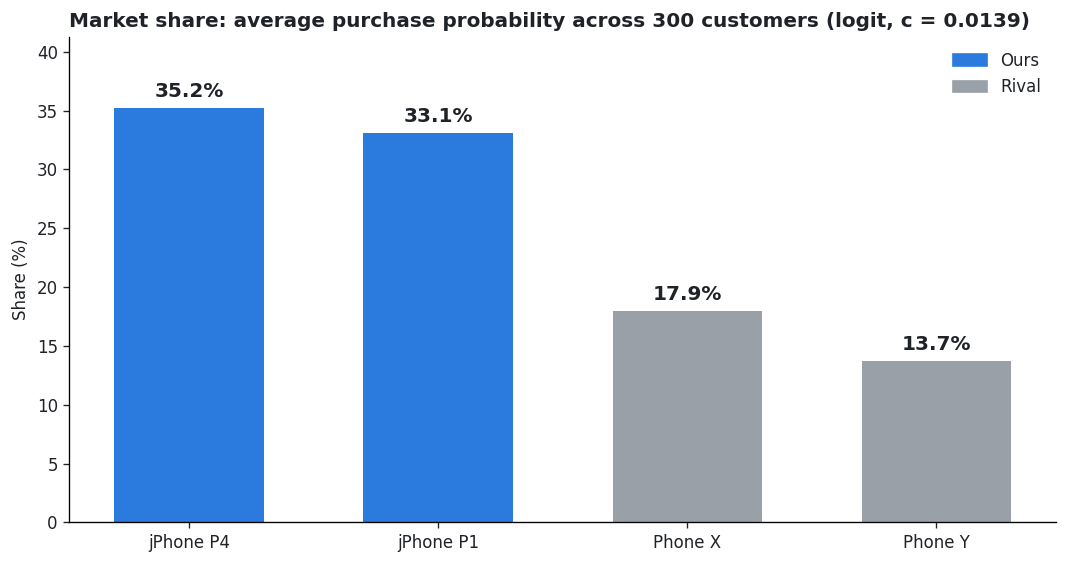

Shares add up to 100%: jPhone P4 35.2%, jPhone P1 33.1%, Phone X 17.9%, Phone Y 13.7%


In [21]:
# ===== 2.4 Market shares =====


OURS_C, RIVAL_C = "#2B7BDE", "#9aa0a8"        # blue: our phones; grey: rivals

share = probs.mean().sort_values(ascending=False)   # each phone's average purchase probability
is_ours = phones["role"].eq("Ours") if "role" in phones.columns else pd.Series(False, index=phones.index)

fig, ax = plt.subplots(figsize=(9, 4.8), facecolor="white")   # white background: readable on dark screens too
ax.set_facecolor("white")
bars = ax.bar(share.index, share.values * 100, width=0.6,
              color=[OURS_C if is_ours[p] else RIVAL_C for p in share.index])
for b, v in zip(bars, share.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.6, f"{v:.1%}",
            ha="center", va="bottom", fontsize=12, fontweight="bold", color=INK)

ax.set_title(f"Market share: average purchase probability across {len(probs)} customers (logit, c = {C})",
             fontsize=12, fontweight="bold", loc="left", color=INK)
ax.set_ylabel("Share (%)", color=INK)
ax.set_ylim(0, share.max() * 100 + 6)
ax.tick_params(colors=INK)
ax.spines[["top", "right"]].set_visible(False)
ax.legend(handles=[Patch(color=OURS_C, label="Ours"), Patch(color=RIVAL_C, label="Rival")],
          loc="upper right", frameon=False, fontsize=10, labelcolor=INK)
plt.tight_layout()
plt.show()

print("Shares add up to", f"{share.sum():.0%}" + ":", ", ".join(f"{p} {s:.1%}" for p, s in share.items()))

In [22]:
# ===== 2.5 One customer, up close =====
# Pick a customer whose choice is split (lowest top probability), so the example shows one person in several segments.
# To look at someone else, set EXAMPLE_ID to their customer_id, e.g. EXAMPLE_ID = "C001".
EXAMPLE_ID = None
cid = EXAMPLE_ID or probs.max(axis=1).idxmin()

# a) Where each utility comes from: importance × rating of the level each phone has, attribute by attribute
rows = {}
for attr, (imp, levels) in ATTRIBUTES.items():
    rows[f"{attr.capitalize()} (importance {cust.at[cid, imp]})"] = [
        f"{show(phones.at[p, attr], attr)}: {cust.at[cid, imp]} × {cust.at[cid, levels[phones.at[p, attr]]]} "
        f"= {W.at[cid, levels[phones.at[p, attr]]]}" for p in phones.index]
breakdown = pd.DataFrame(rows, index=phones.index).T
breakdown.loc["Utility (sum)"] = [f"{U.at[cid, p]:,.0f}" for p in phones.index]
display(breakdown.style
        .set_caption(f"Customer {cid}: level × (importance × rating) for each phone")
        .set_table_styles(TABLE_STYLE))

# b) From utility to probability, stage by stage
stages = pd.DataFrame({
    "Utility":            U.loc[cid],
    "c × utility":        cU.loc[cid],
    "exp(c × utility)":   expU.loc[cid],
    "Probability":        probs.loc[cid],
}).T
stages["Sum"] = [np.nan, np.nan, exp_sum[cid], probs.loc[cid].sum()]
display(stages.style
        .format("{:,.0f}", subset=pd.IndexSlice[["Utility"], :])
        .format("{:.2f}", subset=pd.IndexSlice[["c × utility"], :])
        .format("{:,.1f}", subset=pd.IndexSlice[["exp(c × utility)"], :])
        .format("{:.1%}", subset=pd.IndexSlice[["Probability"], :])
        .format("", na_rep="", subset=pd.IndexSlice[["Utility", "c × utility"], ["Sum"]])
        .set_caption(f"Customer {cid}: from utility to purchase probability (c = {C})")
        .set_table_styles(TABLE_STYLE))

ranked = probs.loc[cid].sort_values(ascending=False)
print(f"Customer {cid} counts as {ranked.iloc[0]:.0%} of a buyer in {ranked.index[0]}'s segment, "
      f"{ranked.iloc[1]:.0%} in {ranked.index[1]}'s, {ranked.iloc[2]:.0%} in {ranked.index[2]}'s "
      f"and {ranked.iloc[3]:.0%} in {ranked.index[3]}'s. No one is dropped from any segment.")

phone,jPhone P4,jPhone P1,Phone X,Phone Y
Brand (importance 19),jPhone: 19 × 3 = 57,jPhone: 19 × 3 = 57,X: 19 × 3 = 57,Y: 19 × 7 = 133
Price (importance 14),"₹30,000: 14 × 3 = 42","₹20,000: 14 × 5 = 70","₹25,000: 14 × 5 = 70","₹30,000: 14 × 3 = 42"
Camera (importance 26),Best: 26 × 6 = 156,Good: 26 × 6 = 156,Good: 26 × 6 = 156,Best: 26 × 6 = 156
Battery (importance 19),2 days: 19 × 6 = 114,2 days: 19 × 6 = 114,2 days: 19 × 6 = 114,1 day: 19 × 3 = 57
Screen (importance 9),"6.8"": 9 × 3 = 27","6.5"": 9 × 5 = 45","6.5"": 9 × 5 = 45","6.8"": 9 × 3 = 27"
Memory (importance 13),512 GB: 13 × 6 = 78,128 GB: 13 × 4 = 52,128 GB: 13 × 4 = 52,256 GB: 13 × 6 = 78
Utility (sum),474,494,494,493


phone,jPhone P4,jPhone P1,Phone X,Phone Y,Sum
Utility,474,494,494,493,
c × utility,6.59,6.87,6.87,6.85,
exp(c × utility),726.8,959.7,959.7,946.4,"3,592.6"
Probability,20.2%,26.7%,26.7%,26.3%,100.0%


Customer C143 counts as 27% of a buyer in jPhone P1's segment, 27% in Phone X's, 26% in Phone Y's and 20% in jPhone P4's. No one is dropped from any segment.


## 3. Profile each affinity segment

Step 2 gave every customer a probability of buying each of the four phones. Each phone now defines a segment: **its affinity segment**, the customers drawn to it. This step describes each segment (what its buyers prefer, and who they are) and finds where each one stands out from the market.

### Every customer counts in every segment, in proportion

There is no hard cut. A customer with a 79% chance of buying jPhone P4 counts as 0.79 of a buyer in P4's segment, and as 0.14, 0.06 and 0.02 of a buyer in the other three. A customer whose chances are split evenly counts about a quarter in each. Nobody is dropped from any segment.

### The segment mean: a probability-weighted average

For each phone's segment, every descriptor is averaged with each customer weighted by their probability of buying that phone:

$$\text{segment mean}_{\text{phone}} = \frac{\sum_{\text{customers}} \text{probability of buying the phone} \times \text{descriptor}}{\sum_{\text{customers}} \text{probability of buying the phone}}$$

In spreadsheet terms: `SUMPRODUCT(probability column, descriptor column) / SUM(probability column)`.

- **Why divide by the sum of probabilities, not by 300?** The sum of probabilities is the phone's *expected number of buyers*. For P4 it is about 106 of the 300 customers. Dividing by it gives the average among the phone's likely buyers. Dividing by 300 would shrink every segment's figures just because its share is smaller.
- **The overall mean** is a plain average of each descriptor across all 300 customers. It is the yardstick every segment is compared with.

### Four parts

1. **Preferences** (3.1): the ratings of each attribute level (1 to 7), the importance of each attribute (out of 100), and importance × rating for each level.
2. **Profile** (3.2): age, income and daily hours on the phone, averaged as they are, and profession and marital status. Each category is turned into a 0/1 column first, so its segment mean reads as a share: 0.27 means 27% of the segment's likely buyers are students.
3. **The segment table** (3.3): both blocks side by side, one row per segment plus the overall average.
4. **Log lifts** (3.4): how far each segment sits from the market average on every descriptor, colour-coded so the focal descriptors stand out.

### 3.1 Segment means on the preference columns

Probability-weighted averages of every rating, importance and importance × rating, one row per segment, with the overall average as the last row. Saved as `seg_pref`. Brand ratings are shaded, because they are read separately in the competitive threat analysis (Step 5).

In [23]:
# ===== 3.1 Segment means on the preference columns =====
# seg mean = SUMPRODUCT(probability, column) / SUM(probability); overall mean = plain average.
pref_cols = (rating_cols                                    # ratings of each level (1–7)
             + imp_cols                                     # importance of each attribute (adds to 100)
             + [f"I*{c}" for c in rating_cols])             # importance × rating of each level
X_pref = pd.concat([cust[rating_cols], cust[imp_cols], W.add_prefix("I*")], axis=1)[pref_cols]

weights = probs / probs.sum()                               # each phone's weights add up to 1
seg_pref = weights.T @ X_pref                               # one row per phone's segment
seg_pref.index = [f"{p} segment" for p in probs.columns]
seg_pref.loc["Overall"] = X_pref.mean()

# Readable view, spreadsheet layout: segments down the side, grouped column headers across the top
attr_of  = {col: (attr, level) for attr, level, col in level_rows}
imp_attr = {imp: attr for attr, (imp, _) in ATTRIBUTES.items()}
def header(c):
    if c in attr_of:  return ("Rating (1–7)", attr_of[c][0].capitalize(), show(attr_of[c][1], attr_of[c][0]))
    if c in imp_attr: return ("Importance (of 100)", imp_attr[c].capitalize(), "")
    a, lv = attr_of[c[2:]]
    return ("Importance × rating", a.capitalize(), show(lv, a))

pref_view = seg_pref.copy()
pref_view.columns = pd.MultiIndex.from_tuples([header(c) for c in pref_cols], names=["Group", "Attribute", "Level"])

BRAND_BG = "#fdf1e3"                                        # brand ratings in light orange, as in the spreadsheet
brand_cols = [col for col in pref_view.columns if col[0] == "Rating (1–7)" and col[1] == "Brand"]
display(pref_view.style
        .format("{:,.2f}")
        .set_properties(**{"background-color": WHITE, "color": INK})
        .set_properties(subset=brand_cols, **{"background-color": BRAND_BG, "color": INK})
        .set_caption("Segment means on the preference columns, with the overall average")
        .set_table_styles(TABLE_STYLE))

print(f"seg_pref: {seg_pref.shape[0]} rows (4 segments + Overall) × {seg_pref.shape[1]} preference columns")

seg_pref: 5 rows (4 segments + Overall) × 40 preference columns


### 3.2 Segment means on the profile columns

The same weights applied to age, income, phone hours, profession and marital status. Numbers are averages; profession and marital status are shares of each segment's likely buyers. Saved as `seg_profile`, with the same rows as `seg_pref`.

In [24]:
# ===== 3.2 Segment means on the profile columns =====
# Same weights as 3.1, so the two blocks are directly comparable.
# Numeric columns are averaged as they are; each category becomes a 0/1 column, so its mean is that category's share.
profile_num = [c for c in NUMERIC_DESCRIPTORS if c not in X_pref.columns]   # skips anything already in seg_pref
dummies = pd.get_dummies(cust[CATEGORICAL_DESCRIPTORS], prefix_sep=": ").astype(int)
X_profile = pd.concat([cust[profile_num], dummies], axis=1)

seg_profile = weights.T @ X_profile                         # one row per phone's segment
seg_profile.index = seg_pref.index[:-1]                     # same row labels as seg_pref
seg_profile.loc["Overall"] = X_profile.mean()

# Readable view: grouped headers; numbers for the numeric columns, percentages for the category shares
NAMES = {"age": "Age (years)", "income_lakh": "Income (₹ lakh a year)", "phone_hours_per_day": "Phone use (hours a day)"}
def header(c):
    if c in profile_num:
        return ("Profile", NAMES.get(c, c))
    var, cat = c.split(": ", 1)
    return (f"{var.replace('_', ' ').capitalize()} (share)", cat)

profile_view = seg_profile.copy()
profile_view.columns = pd.MultiIndex.from_tuples([header(c) for c in X_profile.columns], names=["Group", "Descriptor"])
num_view_cols = [col for col in profile_view.columns if col[0] == "Profile"]
share_cols    = [col for col in profile_view.columns if col[0] != "Profile"]

display(profile_view.style
        .format("{:,.1f}", subset=num_view_cols)
        .format("{:.0%}", subset=share_cols)
        .set_properties(**{"background-color": WHITE, "color": INK})
        .set_caption("Segment means on the profile columns, with the overall average")
        .set_table_styles(TABLE_STYLE))

print(f"seg_profile: {seg_profile.shape[0]} rows (4 segments + Overall) × {seg_profile.shape[1]} profile columns")

seg_profile: 5 rows (4 segments + Overall) × 11 profile columns


### 3.3 The segment table

The two blocks joined side by side into `seg_all`: the four segments and the overall average, across all 51 descriptors (17 ratings, 6 importances, 17 importance × rating values and 11 profile columns). The overall row is shaded; it's the yardstick for the next step. Ratings and importances are shown to two decimals, importance × rating and the profile to one, and profession and marital status as shares.

Each column is tagged with its block, so later steps can show or compare the blocks separately. Two checks run before the log lifts, and print only if something is wrong:
- **No zero or negative means.** A log lift divides a segment mean by the overall mean and takes the log, which is undefined at zero.
- **No duplicate columns.** If two columns hold the same value for every customer (for example, if everyone gives a level the same rating, its importance × rating equals the importance), they would count twice in later comparisons.

In [26]:
# ===== 3.3 The segment table: preferences and profile together =====
assert list(seg_pref.index) == list(seg_profile.index), "The two blocks must have the same rows in the same order."
seg_all = pd.concat([seg_pref, seg_profile], axis=1)
assert not seg_all.columns.duplicated().any(), "A column appears in both blocks."
X_all = pd.concat([X_pref, X_profile], axis=1)

# Which block each column came from (used to show or compare the blocks separately later)
BLOCK = {**{c: "Rating" for c in rating_cols},
         **{c: "Importance" for c in imp_cols},
         **{f"I*{c}": "Importance × rating" for c in rating_cols},
         **{c: "Profile" for c in X_profile.columns}}
block_of = pd.Series(BLOCK).reindex(seg_all.columns)

# Checks before the log lifts
zero_or_less = seg_all.columns[(seg_all <= 0).any()]
if len(zero_or_less):
    print("Warning: these columns have a zero or negative mean somewhere, so their log lift is undefined:",
          ", ".join(zero_or_less))
same = [(a, b) for i, a in enumerate(X_all.columns) for b in X_all.columns[i + 1:] if X_all[a].equals(X_all[b])]
if same:
    print("Note: these columns are identical for every customer, so they would count twice:",
          "; ".join(f"{a} = {b}" for a, b in same))

# Readable headers for every column: (group, attribute or descriptor, level)
NAMES = {"age": "Age (years)", "income_lakh": "Income (₹ lakh a year)", "phone_hours_per_day": "Phone use (hours a day)"}
attr_of  = {col: (attr, level) for attr, level, col in level_rows}
imp_attr = {imp: attr for attr, (imp, _) in ATTRIBUTES.items()}
def full_header(c):
    if c in attr_of:     return ("Rating (1–7)", attr_of[c][0].capitalize(), show(attr_of[c][1], attr_of[c][0]))
    if c in imp_attr:    return ("Importance (of 100)", imp_attr[c].capitalize(), "")
    if c.startswith("I*"):
        a, lv = attr_of[c[2:]]
        return ("Importance × rating", a.capitalize(), show(lv, a))
    if c in profile_num: return ("Profile", NAMES.get(c, c), "")
    var, cat = c.split(": ", 1)
    return (f"{var.replace('_', ' ').capitalize()} (share)", cat, "")
HEADERS = pd.MultiIndex.from_tuples([full_header(c) for c in seg_all.columns], names=["Group", "Descriptor", "Level"])

all_view = seg_all.copy()
all_view.columns = HEADERS
fmt = {}
for c, h in zip(seg_all.columns, HEADERS):
    fmt[h] = "{:.0%}" if h[0].endswith("(share)") else ("{:,.1f}" if block_of[c] in ("Importance × rating", "Profile") else "{:,.2f}")

display(all_view.style
        .format(fmt)
        .set_properties(**{"background-color": WHITE, "color": INK})
        .set_properties(subset=pd.IndexSlice["Overall", :], **{"background-color": HEAD, "color": INK, "font-weight": "700"})
        .set_caption(f"The segment table: {seg_all.shape[0]} rows (4 segments + Overall) × {seg_all.shape[1]} descriptors "
                     f"({', '.join(f'{n} {b.lower()}' for b, n in block_of.value_counts().reindex(['Rating', 'Importance', 'Importance × rating', 'Profile']).items())})")
        .set_table_styles(TABLE_STYLE))

### 3.4 Log lifts: where each segment stands out

A segment's **focal descriptors** are the ones where it sits far from the market. The log lift measures that gap for every segment and every descriptor:

$$\text{log lift} = \log_{10}\left(\frac{\text{segment mean}}{\text{overall mean}}\right)$$

- **0** means the segment matches the market. **+0.10** is about 26% above it; **−0.10** about 21% below.
- **Why a ratio, not a difference?** Descriptors come in different units: rupees, years, hours, shares, importance points. A ratio puts them all on one scale, so an income gap and a profession gap can be compared directly.
- **Why the log?** It makes above and below symmetric: twice the market average is +0.30, and half of it is −0.30. On a plain ratio, "half" (0.5) would look like a smaller gap than "double" (2.0).

**Reading the colours:** green is well above the market (log lift ≥ +0.10), red is well below (≤ −0.10), and yellow is close to it. Read each segment's row for its greens and reds: those are its focal descriptors, and the raw material for its persona. Comparing rows by colour also shows which segments resemble each other. That is Approach 3 of the competitive threat analysis.

A caution from the method itself: a ratio is strictly meaningful only for measures with a true zero (income, age, hours, shares). The 1–7 ratings have no true zero, so their log lifts are read as a guide, not exactly. This is common practice.

In [30]:
# ===== 3.4 Log lifts: how far each segment sits from the market average =====
# log lift = log10(segment mean / overall mean): 0 = same as the market, +0.10 ≈ 26% above, −0.10 ≈ 21% below.
segments = seg_all.index[:-1]
lift_cols = seg_all.columns[(seg_all > 0).all()]            # log lift needs positive means (see the check in 3.3)
log_lift = np.log(seg_all.loc[segments, lift_cols] / seg_all.loc["Overall", lift_cols]) / np.log(LOG_BASE)

# Colour code: solid cell colours, bold white numbers.
# green = well above the market, orange = close to the market, red = well below.
GREEN, ORANGE, RED = "#2e9e6a", "#e8822e", "#d64545"
def band(v):
    colour = GREEN if v >= FOCAL_CUTOFF else (RED if v <= -FOCAL_CUTOFF else ORANGE)
    return f"background-color:{colour} !important; color:#ffffff !important; font-weight:700 !important"

lift_view = log_lift.copy()
lift_view.columns = HEADERS[[list(seg_all.columns).index(c) for c in lift_cols]]
display(lift_view.style
        .map(band)
        .format("{:+.2f}")
        .set_caption(f"Log lifts (log{LOG_BASE}): green ≥ +{FOCAL_CUTOFF:.2f} (well above the market), "
                     f"red ≤ −{FOCAL_CUTOFF:.2f} (well below), orange in between (close to the market)")
        .set_table_styles(TABLE_STYLE))

focal = (log_lift.abs() >= FOCAL_CUTOFF).sum(axis=1)
print("Focal descriptors per segment (|log lift| ≥ " + f"{FOCAL_CUTOFF:.2f}): "
      + ", ".join(f"{s.replace(' segment', '')} {n}" for s, n in focal.items()))

Focal descriptors per segment (|log lift| ≥ 0.10): jPhone P4 11, jPhone P1 12, Phone X 6, Phone Y 12


#### How to read this chart
Each row is one phone's **affinity segment**: all 300 customers, each counted in proportion to their chance of buying that phone. Each column is something about those customers: what matters to them, which brands they like, and who they are. The number in each cell is the **log lift**, how far the segment's average sits from the market's average:
- **0** means the segment matches the market; **+0.10** is about 26% above it, **−0.10** about 21% below.
- **Green** is well above the market, **red** well below, **yellow** close to it.

Read **across a row** to see what makes a segment stand out: its greens and reds are its **focal descriptors**. Read **down the rows** to see which segments look alike and which are opposites.

#### What it shows
- **jPhone P4's buyers** care less about price than the market (−0.17) and more about screen (+0.13) and memory (+0.10). They earn more (+0.12), and lean towards IT and tech professionals (+0.20). There are few students (−0.26) or field-sales staff (−0.12) among them.
- **jPhone P1's buyers** are the opposite: price matters more (+0.14), screen and memory less (−0.14, −0.10). Their income is lower (−0.15), more of them are students (+0.16) and field-sales staff (+0.10), and fewer are IT professionals (−0.28) or creative professionals (−0.18).
- **Phone X's buyers** follow P1's pattern, but more weakly. They lean to field sales (+0.18), with few IT professionals (−0.21), and screen size matters less to them (−0.13).
- **Phone Y's buyers** care about the camera (+0.16), and much less about battery (−0.15) or price (−0.16). They lean strongly to creative and media professionals (+0.27), with almost no field-sales staff (−0.52) and few business owners (−0.19).
- **Brand preference, age, phone hours and marital status stay yellow** for every segment. They don't separate the segments here, so the personas rest on what customers value and what they do for a living.

#### The takeaway
Each segment has a clear persona, built from data rather than opinion:
- **P4:** the well-paid tech professional who wants a big screen and lots of storage, and will pay for it.
- **P1:** the student or field-sales buyer for whom price decides.
- **Phone X:** the field-sales professional.
- **Phone Y:** the creative professional who buys for the camera.

The colours also show the competition:
- **P1 shares Phone X's pattern** (4 strong matches, no opposites): they compete for the same price-led buyers.
- **P4 shares Phone Y's low price sensitivity and higher income**, but not its camera focus: they compete for the same buyers who will pay more.
- **P1 and P4 are opposites** (6 opposites, no matches): the two jPhones speak to different people and won't eat into each other's sales.

### 3.5 Focal descriptors: what makes each segment stand out

The greens and reds from 3.4, pulled out segment by segment and put in plain words: what each segment's likely buyers have **more** of than the market (log lift ≥ +0.10), and what they have **less** of (≤ −0.10), biggest first. These are the raw material for the personas.

In [31]:
# ===== 3.5 Focal descriptors: what makes each segment stand out =====
# A descriptor is focal for a segment if its log lift is at least +FOCAL_CUTOFF or at most −FOCAL_CUTOFF.

def plain(col, up):
    """Describe one descriptor in plain words, for a log lift above (up=True) or below the market."""
    more, less = ("more", "less") if up else ("less", "more")
    if col in imp_attr:                                   # importance of an attribute
        return f"{imp_attr[col].capitalize()} matters {more}"
    if col in attr_of:                                    # rating of a level
        a, lv = attr_of[col]
        return f"Rates {show(lv, a)} ({a}) {'higher' if up else 'lower'}"
    if col.startswith("I*"):                              # importance × rating of a level
        a, lv = attr_of[col[2:]]
        return f"Values {show(lv, a)} ({a}) {more} (importance × rating)"
    if col in profile_num:                                # numeric profile
        words = {"age": ("Older", "Younger"), "income_lakh": ("Higher income", "Lower income"),
                 "phone_hours_per_day": ("More time on the phone", "Less time on the phone")}
        hi, lo = words.get(col, (f"Higher {col}", f"Lower {col}"))
        return hi if up else lo
    var, cat = col.split(": ", 1)                         # share of a category
    return f"{'More' if up else 'Fewer'} {GROUP_WORDS.get(cat, cat.lower())}"

# How each category reads as a group of people (fallback: the category name in lower case)
GROUP_WORDS = {"Student": "students", "IT / tech professional": "IT / tech professionals",
               "Creative / media": "creative / media professionals", "Field sales": "field-sales staff",
               "Business owner": "business owners", "Other salaried": "other salaried staff",
               "Married": "married customers", "Single": "single customers"}

rows = []
for seg in log_lift.index:
    lifts = log_lift.loc[seg]
    above = lifts[lifts >= FOCAL_CUTOFF].sort_values(ascending=False)
    below = lifts[lifts <= -FOCAL_CUTOFF].sort_values()
    rows.append({
        "Segment": seg,
        "Stands out for (well above the market)":     "<br>".join(f"{plain(c, True)} ({v:+.2f})" for c, v in above.items()) or "—",
        "Stands out against (well below the market)": "<br>".join(f"{plain(c, False)} ({v:+.2f})" for c, v in below.items()) or "—",
    })
focal_table = pd.DataFrame(rows).set_index("Segment")

display(focal_table.style
        .set_properties(**{"text-align": "left", "vertical-align": "top", "line-height": "1.5"})
        .set_caption(f"Focal descriptors by segment: |log lift| ≥ {FOCAL_CUTOFF:.2f}, biggest first")
        .set_table_styles(TABLE_STYLE + [{"selector": "td", "props": "text-align:left; vertical-align:top"}]))

,Stands out for (well above the market),Stands out against (well below the market)
Segment,,
jPhone P4 segment,"More IT / tech professionals (+0.20)Values 6.8"" (screen) more (importance × rating) (+0.19)Screen matters more (+0.13)Values 512 GB (memory) more (importance × rating) (+0.12)Higher income (+0.12)Values 6.5"" (screen) more (importance × rating) (+0.11)","Fewer students (-0.26)Values ₹20,000 (price) less (importance × rating) (-0.20)Values ₹25,000 (price) less (importance × rating) (-0.20)Price matters less (-0.17)Fewer field-sales staff (-0.12)"
jPhone P1 segment,"Values ₹20,000 (price) more (importance × rating) (+0.17)More students (+0.16)Values ₹25,000 (price) more (importance × rating) (+0.15)Price matters more (+0.14)More field-sales staff (+0.10)","Fewer IT / tech professionals (-0.28)Values 6.8"" (screen) less (importance × rating) (-0.23)Fewer creative / media professionals (-0.18)Lower income (-0.15)Screen matters less (-0.14)Values 512 GB (memory) less (importance × rating) (-0.12)Values 6.5"" (screen) less (importance × rating) (-0.11)"
Phone X segment,More field-sales staff (+0.18),"Values 6.8"" (screen) less (importance × rating) (-0.21)Fewer IT / tech professionals (-0.21)Screen matters less (-0.13)Values 512 GB (memory) less (importance × rating) (-0.11)Fewer creative / media professionals (-0.11)"
Phone Y segment,More creative / media professionals (+0.27)Values Best (camera) more (importance × rating) (+0.18)Camera matters more (+0.16)Values Good (camera) more (importance × rating) (+0.16)Values Y (brand) more (importance × rating) (+0.11),"Fewer field-sales staff (-0.52)Values ₹20,000 (price) less (importance × rating) (-0.19)Fewer business owners (-0.19)Values ₹25,000 (price) less (importance × rating) (-0.18)Values 2 days (battery) less (importance × rating) (-0.17)Price matters less (-0.16)Battery matters less (-0.15)"


#### The personas

Built only from each segment's focal descriptors above:

- **jPhone P4: the well-paid tech professional.** Wants a big screen and plenty of storage, and price matters less. More IT and tech professionals and higher incomes than the market; few students or field-sales staff.
- **jPhone P1: the price-led buyer.** Price decides; screen size and storage matter less. More students and field-sales staff, lower incomes, few IT or creative professionals.
- **Phone X: the field-sales professional.** The segment with the fewest focal descriptors: more field-sales staff, and less interest in a big screen or storage. A milder version of P1's buyers.
- **Phone Y: the creative professional.** Buys for the camera; price and battery life matter less. Many more creative and media professionals; almost no field-sales staff.

## 4. Read the competition, three ways

The segments tell us who our buyers are. This step asks **who else is competing for them**: the obvious rivals, and the less obvious ones where a small move by a rival could cost us share.

The same question is answered three ways, each from a different angle:

| | Approach | Compares | How | Tells you |
|---|---|---|---|---|
| 4.1 | **Purchase probabilities** | Each phone's column of 300 purchase probabilities | Cosine similarity | **Whether** two phones compete: are the same customers likely to buy both? |
| 4.2 | **Brand preference table** | How each segment's buyers rate each brand | Cosine similarity | **Why**: is the overlap down to brand taste, or only to the specs? |
| 4.3 | **Segment profiles** | The log-lift rows from Step 3 | Observation: colour matches and opposites | **How** the buyers differ: what they value, and who they are |

Approaches 1 and 2 use **cosine similarity**, a standard measure of how alike two lists of numbers are:

$$\text{cosine}(A, B) = \frac{A \cdot B}{\lVert A \rVert \times \lVert B \rVert}$$

It runs from −1 to 1. Close to **1** means the two lists rise and fall together; **0** means they are unrelated; **below 0** means one tends to be high where the other is low.

Approach 3 needs no formula. It reads the colour-coded log-lift table directly: where two segments are both green or both red on the same descriptor, their buyers are alike; where one is green and the other red, they are opposites. Observation keeps the reasons in view (*which* traits match), which a single similarity number would hide.

If the three approaches agree, the finding is robust. One limit applies to all three: they show that two phones compete, not which one threatens the other more. Step 5 looks at that direction.

### 4.1 Approach 1: Purchase probabilities

Each phone is a column of 300 purchase probabilities, one per customer (from 2.3.5). If two phones' columns are high for the same customers and low for the same customers, those customers are weighing up both phones: the phones compete.

1. **The probability columns** (4.1a): the first ten customers' chances of buying each phone.
2. **Cosine similarity** (4.1b): every phone compared with the other three. Each phone's closest rival is shown in blue.

In [32]:
# ===== 4.1a Each phone as a column of purchase probabilities =====
# Each phone is a vector of 300 numbers: every customer's chance of buying it (from 2.3.5).
N_PROB = 10
print(f"Each phone is a column of {len(probs)} purchase probabilities, one per customer. First {N_PROB} customers:")
display(probs.head(N_PROB).style
        .format("{:.3f}")
        .set_caption(f"Purchase probabilities of the four phones, first {N_PROB} of {len(probs)} customers")
        .set_table_styles(TABLE_STYLE))

Each phone is a column of 300 purchase probabilities, one per customer. First 10 customers:


phone,jPhone P4,jPhone P1,Phone X,Phone Y
customer_id,,,,
C001,0.788,0.057,0.018,0.137
C002,0.481,0.087,0.053,0.380
C003,0.232,0.398,0.356,0.014
C004,0.382,0.238,0.238,0.142
C005,0.019,0.291,0.671,0.019
C006,0.344,0.354,0.291,0.011
C007,0.026,0.740,0.221,0.012
C008,0.375,0.258,0.218,0.150
C009,0.685,0.137,0.054,0.124


In [33]:
# ===== 4.1b Cosine similarity between the phones' probability columns =====
# cosine(A, B) = (A · B) / (|A| × |B|): close to 1 = the same customers are likely to buy both phones.
def cosine_matrix(M):
    """Cosine similarity between every pair of columns of M."""
    V = M.to_numpy(dtype=float)
    norms = np.linalg.norm(V, axis=0)
    return pd.DataFrame((V.T @ V) / np.outer(norms, norms), index=M.columns, columns=M.columns)

sim_prob = cosine_matrix(probs)

# Each phone's closest other phone (its main competitor on this measure)
off_diag = sim_prob.where(~np.eye(len(sim_prob), dtype=bool))
closest = off_diag.idxmax(axis=1)

HIGHLIGHT = "background-color:#2B7BDE !important; color:#ffffff !important; font-weight:700 !important"
def mark(row):
    return [HIGHLIGHT if col == closest[row.name] else "" for col in row.index]

display(off_diag.style
        .apply(mark, axis=1)
        .format("{:.2f}", na_rep="—")
        .set_caption("Approach 1 · Cosine similarity of purchase probabilities (each phone vs the other three; "
                     "blue = closest)")
        .set_table_styles(TABLE_STYLE))

ours = phones.index[phones["role"] == "Ours"] if "role" in phones.columns else phones.index
for p in ours:
    others = off_diag.loc[p].drop(p).sort_values(ascending=False)
    print(f"{p}: closest to {others.index[0]} ({others.iloc[0]:.2f}), then "
          + ", ".join(f"{q} ({v:.2f})" for q, v in others.iloc[1:].items()) + ".")

phone,jPhone P4,jPhone P1,Phone X,Phone Y
phone,,,,
jPhone P4,—,0.34,0.44,0.70
jPhone P1,0.34,—,0.81,0.29
Phone X,0.44,0.81,—,0.41
Phone Y,0.70,0.29,0.41,—


jPhone P4: closest to Phone Y (0.70), then Phone X (0.44), jPhone P1 (0.34).
jPhone P1: closest to Phone X (0.81), then jPhone P4 (0.34), Phone Y (0.29).


#### What Approach 1 says

- **jPhone P1 competes with Phone X (0.81).** The customers likely to buy P1 are the same ones likely to buy X. That makes sense: P1 has X's specs at ₹5,000 less, so they're fishing in the same pond, and P1 wins on price.
- **jPhone P4 competes with Phone Y (0.70).** P4's likely buyers are Phone Y's likely buyers: both sell at ₹30,000 with a big screen and the best camera. P4 adds a 2-day battery and 512 GB.
- **The two jPhones barely overlap (0.34).** P1 and P4 draw different customers, so launching both adds reach without much cannibalisation.
- **The rivals confirm it from their side.** Phone X's closest phone is P1, and Phone Y's is P4.

This is the most direct measure of competition, because purchase probability is what drives share. It says *whether* phones compete. Approaches 2 and 3 show *why*.

### 4.2 Approach 2: The brand preference table

Approach 1 showed *which* phones compete. This approach asks *why*: is the overlap down to how buyers weigh the brands, or only to the specs?

It starts from one small table: each segment's average **importance × rating** for each brand, with the market average as the last row. Importance × rating combines how much brand matters to a customer with how much they like each brand, so it shows **how much each brand counts in the segment's choice**.

The table is read two ways:
- **By rows** (4.2b): whose buyers weigh the brands most alike? This is about **customers**, so it guides **targeting**: whose customers to go after.
- **By columns** (4.2c): which brands count for the same segments? This is about **brands**, so it guides **competitive defence**: whose moves to watch.

**Why centre on the market average?** Every value in the table is positive, so every row and column points in roughly the same direction, and the raw cosines all come out near 1. Subtracting the market average compares each segment *above or below the market* instead, and the differences show.

In [37]:
# ===== 4.2a The brand preference table: importance × rating of each brand =====
# Each segment's probability-weighted average of importance × rating for each brand (from the segment table, 3.3),
# with the overall (market) mean as the last row. This is how much each brand counts in the segment's choice.
brand_levels = ATTRIBUTES["brand"][1]                        # {"jPhone": "brand_jPhone", "X": "brand_X", "Y": "brand_Y"}
brand_table = seg_all[[f"I*{col}" for col in brand_levels.values()]].copy()
brand_table.columns = list(brand_levels)                     # jPhone, X, Y
brand_table.index = [s.replace(" segment", "'s buyers") if s != "Overall" else "Overall (market)" for s in seg_all.index]

TOP = "background-color:#2B7BDE !important; color:#ffffff !important; font-weight:700 !important"
def mark_top(row):                                           # each segment's strongest brand in blue
    if row.name.startswith("Overall"):
        return [f"background-color:{HEAD} !important; font-weight:700" for _ in row]
    return [TOP if v == row.max() else "" for v in row]

display(brand_table.style
        .apply(mark_top, axis=1)
        .format("{:.1f}")
        .set_caption("Approach 2 · Brand: importance × rating by segment, with the market mean "
                     "(blue = the brand that counts most for the segment)")
        .set_table_styles(TABLE_STYLE))

,jPhone,X,Y
jPhone P4's buyers,56.7,53.2,54.4
jPhone P1's buyers,40.1,51.0,45.9
Phone X's buyers,40.7,56.0,51.8
Phone Y's buyers,47.2,55.5,67.9
Overall (market),47.1,53.3,53.0


In [39]:
# ===== 4.2b Read by rows: whose buyers weigh the brands most alike? =====
segs = brand_table.drop(index="Overall (market)")
market_avg = brand_table.loc["Overall (market)"]

def show_sim(sim, caption, highlight=True):
    """Display a similarity matrix with the diagonal blanked and, if asked, each row's closest in blue."""
    off = sim.where(~np.eye(len(sim), dtype=bool))
    near = off.idxmax(axis=1)
    display(off.style
            .apply(lambda row: [TOP if highlight and c == near[row.name] else "" for c in row.index], axis=1)
            .format("{:.2f}", na_rep="—")
            .set_caption(caption)
            .set_table_styles(TABLE_STYLE))
    return off

# 1. Raw values: every pair comes out near 1, because all the values are positive and point the same way
row_raw = show_sim(cosine_matrix(segs.T), "Rows, raw values: everything looks alike (all values are positive)",
                   highlight=False)

# 2. Centred on the market mean: compares each segment ABOVE or BELOW the market on each brand
row_centred = show_sim(cosine_matrix((segs - market_avg).T),
                       "Rows, centred on the market mean: whose buyers weigh the brands most alike (blue = closest)")

for seg in [s for s in row_centred.index if s.startswith("jPhone")]:
    others = row_centred.loc[seg].drop(seg).sort_values(ascending=False)
    print(f"{seg}: closest to {others.index[0]} ({others.iloc[0]:+.2f}), then "
          + ", ".join(f"{q} ({v:+.2f})" for q, v in others.iloc[1:].items()) + ".")

,jPhone P4's buyers,jPhone P1's buyers,Phone X's buyers,Phone Y's buyers
jPhone P4's buyers,—,0.99,0.99,0.99
jPhone P1's buyers,0.99,—,1.00,0.99
Phone X's buyers,0.99,1.00,—,0.99
Phone Y's buyers,0.99,0.99,0.99,—


,jPhone P4's buyers,jPhone P1's buyers,Phone X's buyers,Phone Y's buyers
jPhone P4's buyers,—,-0.77,-0.92,0.15
jPhone P1's buyers,-0.77,—,0.65,-0.73
Phone X's buyers,-0.92,0.65,—,-0.12
Phone Y's buyers,0.15,-0.73,-0.12,—


jPhone P4's buyers: closest to Phone Y's buyers (+0.15), then jPhone P1's buyers (-0.77), Phone X's buyers (-0.92).
jPhone P1's buyers: closest to Phone X's buyers (+0.65), then Phone Y's buyers (-0.73), jPhone P4's buyers (-0.77).


In [40]:
# ===== 4.2c Read by columns: which brands count for the same segments? =====
col_centred = show_sim(cosine_matrix(segs - market_avg),
                       "Columns, centred on the market mean: which brands count for the same segments (blue = closest)")

our_brand = "jPhone"
others = col_centred.loc[our_brand].drop(our_brand).sort_values(ascending=False)
print(f"The jPhone brand counts for the same segments as {others.index[0]} ({others.iloc[0]:+.2f}), "
      f"far more than {others.index[1]} ({others.iloc[1]:+.2f}).")

# Plain observation: for each jPhone segment, which brand counts most, and where does jPhone stand vs the market?
for seg in [s for s in segs.index if s.startswith("jPhone")]:
    fav = segs.loc[seg].idxmax()
    ours = f"jPhone {segs.loc[seg, our_brand]:.1f} (market {market_avg[our_brand]:.1f})"
    if fav == our_brand:
        print(f"{seg}: jPhone counts most, {ours}.")
    else:
        print(f"{seg}: {fav} counts most ({segs.loc[seg, fav]:.1f}), ahead of {ours}.")

,jPhone,X,Y
jPhone,—,-0.03,0.32
X,-0.03,—,0.66
Y,0.32,0.66,—


The jPhone brand counts for the same segments as Y (+0.32), far more than X (-0.03).
jPhone P4's buyers: jPhone counts most, jPhone 56.7 (market 47.1).
jPhone P1's buyers: X counts most (51.0), ahead of jPhone 40.1 (market 47.1).


#### What Approach 2 says

**Rows: whose buyers are most like ours? (targeting)**
- **P1's buyers weigh the brands most like Phone X's buyers (+0.65).** Both give brand X more weight than jPhone, and P1's buyers give every brand less weight than the market: brand simply matters less to them. P1's campaign should give Phone X's customers a reason to switch, and lead with price, not brand.
- **P4's buyers are closest to Phone Y's buyers (+0.15), and furthest from X's (−0.92).** P4's buyers are the only segment where jPhone counts above the market (56.7 against 47.1). Y's buyers are their nearest match, so P4's campaign should target Phone Y's customers.

**Columns: which brand is substitutable with ours? (competitive defence)**
- **The jPhone brand counts for the same segments as Phone Y (+0.32), not Phone X (−0.03).** Where jPhone matters, Y matters too. Y is the brand to watch for P4.
- **P1 wins on price, not on brand.** For P1's buyers, brand X counts for more (51.0) than jPhone (40.1). If Phone X closes the ₹5,000 price gap, P1 has little brand pull to fall back on. That's the non-obvious threat.

**Summary:** P1's rival is Phone X, and P4's is Phone Y, the same as Approach 1. For P4 and Y, how buyers weigh the brands genuinely overlaps. For P1 and X, the overlap is about price, and X's brand actually counts for more.

**Why the raw cosines don't work:** without centring, every pair scores about 0.99, because all the values are positive. Centring on the market average is what makes this table readable.

### 4.3 Approach 3: Segment profiles, compared by observation

Approaches 1 and 2 put a number on similarity. This approach reads the segments' profiles directly, the way a manager would scan the colour-coded table from Step 3, and keeps the reasons in view: *which* traits two segments share, and *which* they are opposite on.

**The descriptors: 19, each trait counted once.**
- 6 importances: how much price, camera, battery, screen, memory and brand matter.
- 3 brands: how much each brand counts (importance × rating, as in 4.2).
- 10 profile items: age, income, daily phone hours, the share of each of six professions, and the share married.

The level ratings and the other importance × rating columns from Step 3 are left out here. They repeat the importances (a price-sensitive segment shows up on importance of price *and* on every price level), so including them would count the same trait several times. "Single" is left out because it simply mirrors "Married".

**How to read it.** Using the colours from 3.4 (green well above the market, red well below, orange close to it), compare two segments descriptor by descriptor:
- **Strong match:** both green, or both red. The two segments' buyers stand out from the market in the same way.
- **Opposite:** one green, the other red.
- **Orange next to orange doesn't count:** both being close to the market isn't a shared trait.

Many strong matches and no opposites means the two segments are drawing on the same kind of customer: the phones compete for them.

In [41]:
# ===== 4.3 Approach 3: segment profiles, compared by observation =====
# 19 descriptors, each trait counted once: 6 importances, 3 brands (importance × rating, as in 4.2), 10 profile items.
APPROACH3_COLS = (imp_cols
                  + [f"I*{col}" for col in ATTRIBUTES["brand"][1].values()]
                  + profile_num
                  + [c for c in X_profile.columns if c not in profile_num and c != "marital_status: Single"])  # Single mirrors Married
LABEL3 = {**{imp: f"{a.capitalize()} matters" for a, (imp, _) in ATTRIBUTES.items()},
          **{f"I*{col}": f"{b} brand counts" for b, col in ATTRIBUTES["brand"][1].items()},
          "age": "Age", "income_lakh": "Income", "phone_hours_per_day": "Phone hours a day",
          **{c: (lambda w: w[0].upper() + w[1:])(GROUP_WORDS.get(c.split(": ", 1)[1], c.split(": ", 1)[1]))
             for c in X_profile.columns if c not in profile_num}}

lifts3 = log_lift[APPROACH3_COLS].copy()
lifts3.index = [s.replace(" segment", "") for s in lifts3.index]
colour = lifts3.apply(lambda s: np.where(s >= FOCAL_CUTOFF, "G", np.where(s <= -FOCAL_CUTOFF, "R", "O")))

# 1. The 19 log lifts, one column per segment, coloured as in 3.4 (green above, red below, orange close to the market)
view3 = lifts3.T.copy()
view3.index = [LABEL3[c] for c in APPROACH3_COLS]
display(view3.style
        .map(band)
        .format("{:+.2f}")
        .set_caption(f"Approach 3 · The 19 descriptors by segment (log lift; green ≥ +{FOCAL_CUTOFF:.2f}, "
                     f"red ≤ −{FOCAL_CUTOFF:.2f}, orange close to the market)")
        .set_table_styles(TABLE_STYLE))

# 2. Count, for each pair of segments, the strong colour matches and the opposites
def compare(a, b):
    ca, cb = colour.loc[a], colour.loc[b]
    match    = [c for c in APPROACH3_COLS if ca[c] == cb[c] != "O"]
    opposite = [c for c in APPROACH3_COLS if {ca[c], cb[c]} == {"G", "R"}]
    return match, opposite

segs3 = list(lifts3.index)
pairs = [(a, b) for i, a in enumerate(segs3) for b in segs3[i + 1:]]
rows = []
for a, b in pairs:
    match, opposite = compare(a, b)
    rows.append({"Pair": f"{a} vs {b}", "Strong matches": len(match), "Opposites": len(opposite),
                 "Matching traits": "<br>".join(f"{LABEL3[c]} ({'both above' if colour.loc[a, c] == 'G' else 'both below'})"
                                                for c in match) or "—",
                 "Opposite traits": "<br>".join(f"{LABEL3[c]} ({a.split()[-1]} {'above' if colour.loc[a, c] == 'G' else 'below'})"
                                                for c in opposite) or "—"})
pair_table = pd.DataFrame(rows).set_index("Pair").sort_values(["Strong matches", "Opposites"], ascending=[False, True])

display(pair_table.style
        .set_properties(subset=["Matching traits", "Opposite traits"], **{"text-align": "left", "vertical-align": "top"})
        .set_caption(f"Colour matches and opposites across the {len(APPROACH3_COLS)} descriptors "
                     "(a match = both green or both red; orange next to orange does not count)")
        .set_table_styles(TABLE_STYLE))

# 3. Each of our segments: the rival it shares most with
for seg in [s for s in segs3 if s.startswith("jPhone")]:
    scores = {o: compare(seg, o) for o in segs3 if o != seg}
    best = max(scores, key=lambda o: (len(scores[o][0]), -len(scores[o][1])))
    print(f"{seg}: most alike {best} ({len(scores[best][0])} matches, {len(scores[best][1])} opposites).")

,jPhone P4,jPhone P1,Phone X,Phone Y
Brand matters,+0.02,-0.04,-0.01,+0.05
Price matters,-0.17,+0.14,+0.06,-0.16
Camera matters,-0.01,-0.06,-0.02,+0.16
Battery matters,-0.04,+0.04,+0.09,-0.15
Screen matters,+0.13,-0.14,-0.13,+0.03
Memory matters,+0.10,-0.10,-0.08,+0.02
jPhone brand counts,+0.08,-0.07,-0.06,+0.00
X brand counts,-0.00,-0.02,+0.02,+0.02
Y brand counts,+0.01,-0.06,-0.01,+0.11
Age,+0.02,-0.02,+0.01,-0.02


,Strong matches,Opposites,Matching traits,Opposite traits
Pair,,,,
jPhone P1 vs Phone X,4,0,Screen matters (both below)Creative / media professionals (both below)Field-sales staff (both above)IT / tech professionals (both below),—
jPhone P4 vs Phone Y,2,0,Price matters (both below)Field-sales staff (both below),—
Phone X vs Phone Y,0,2,—,Creative / media professionals (X below)Field-sales staff (X above)
jPhone P4 vs Phone X,0,3,—,Screen matters (P4 above)Field-sales staff (P4 below)IT / tech professionals (P4 above)
jPhone P1 vs Phone Y,0,3,—,Price matters (P1 above)Creative / media professionals (P1 below)Field-sales staff (P1 above)
jPhone P4 vs jPhone P1,0,6,—,Price matters (P4 below)Screen matters (P4 above)Income (P4 above)Field-sales staff (P4 below)IT / tech professionals (P4 above)Students (P4 below)


jPhone P4: most alike Phone Y (2 matches, 0 opposites).
jPhone P1: most alike Phone X (4 matches, 0 opposites).


#### What Approach 3 says

- **P1's buyers and Phone X's buyers are the same kind of customer** (4 matches, no opposites). Both have more field-sales staff and fewer IT and creative professionals than the market, and both care less about screen size. They're the practical, price-led buyer.
- **P4's buyers and Phone Y's buyers share what they don't care about** (2 matches, no opposites). Price matters less to both, and both have few field-sales staff. But they differ on what the phone is *for*: P4's buyers want screen and memory, Y's want the camera. That's a weaker bond than P1 and X, and it's the opening for P4's message: Y's buyers will pay ₹30,000, so give them more for it.
- **The two jPhones are opposites** (6 opposites, no matches): on price, screen, income, students, field sales and IT professionals. They speak to different people, which is what you want from a two-phone range.
- **No rival is a match for both jPhones.** Every other pair has opposites and no matches.

**Agreement across the three approaches:** P1 competes with Phone X, and P4 with Phone Y, on purchase probabilities (4.1), on how buyers weigh the brands (4.2), and on who the buyers are (4.3). Three different angles, one answer, so the finding is robust.

## 5. The asymmetry of competition

The two Approach 2 tables, reproduced from 4.2b and 4.2c (centred on the market average; each row's closest match in **bold**):

**By rows: whose buyers weigh the brands alike?**

| | jPhone P4's buyers | jPhone P1's buyers | Phone X's buyers | Phone Y's buyers |
|---|---|---|---|---|
| **jPhone P4's buyers** | — | −0.77 | −0.92 | **+0.15** |
| **jPhone P1's buyers** | −0.77 | — | **+0.65** | −0.73 |
| **Phone X's buyers** | −0.92 | **+0.65** | — | −0.12 |
| **Phone Y's buyers** | **+0.15** | −0.73 | −0.12 | — |

**By columns: which brands count for the same buyers?**

| | jPhone brand | Brand X | Brand Y |
|---|---|---|---|
| **jPhone brand** | — | −0.03 | **+0.32** |
| **Brand X** | −0.03 | — | **+0.66** |
| **Brand Y** | +0.32 | **+0.66** | — |

**Reading the asymmetry.** A similarity score is the same both ways: jPhone is as similar to Y (+0.32) as Y is to jPhone. But competition is about who your *closest* rival is, and that need not be mutual:

- **Between the buyers (rows), the pairs are mutual.** P1's buyers are closest to X's buyers, and X's buyers are closest to P1's. P4's buyers and Y's buyers are each other's closest. Each jPhone and its rival are fishing in the same pond.
- **Between the brands (columns), they are not.** For the **jPhone brand, Y is the closest rival** (+0.32). But for **brand Y, the closest rival is X** (+0.66), not jPhone. Y sees X as its main competitor; jPhone is only second.

**What it means:** jPhone has to watch Phone Y, but Phone Y is watching Phone X. P4 can take buyers from Y while Y's attention is on X. But if Y turns its attention to P4, P4 is exposed: P4's buyers already lean towards brand Y (54.4 against the market's 53.0), while Y's buyers are neutral about jPhone (47.2 against 47.1). And for P1, brand works against it both ways: P1's own buyers weigh brand X (51.0) well above jPhone (40.1). If Phone X closes the ₹5,000 price gap, P1 has little to hold its buyers with.

**Summary:** jPhone competes with Y, but Y competes with X. Defend P4 on its features, and defend P1 on price.

### End of code